In [4]:
from tensorflow import keras
from tensorflow.keras import layers

In [5]:
model = keras.models.load_model("./drowsiness_model.h5")

d:\anaconda_python\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
d:\anaconda_python\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


In [6]:

#LOADING AND PREPROCESSING TEST DATA

import numpy as np
import os
import cv2
from sklearn.model_selection import train_test_split

# Define dataset path
data_dir = "./Dataset" 
categories = ["Drowsy", "Non Drowsy"]
IMG_SIZE = 128

# Load test dataset
test_data = []
test_labels = []

for category in categories:
    path = os.path.join(data_dir, category)  
    label = categories.index(category)  # Convert category to numerical label (0 or 1)

    for img_name in os.listdir(path):
        img_path = os.path.join(path, img_name)
        img = cv2.imread(img_path)

        if img is not None:
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))  # Resize
            img = img / 255.0  # Normalize pixel values
            test_data.append(img)
            test_labels.append(label)

# Convert to numpy arrays
X_test = np.array(test_data, dtype="float32")
y_test = np.array(test_labels, dtype="int")

# Print dataset shape
print(f"✅ Test Data Shape: {X_test.shape}, Labels Shape: {y_test.shape}")


✅ Test Data Shape: (41793, 128, 128, 3), Labels Shape: (41793,)


In [7]:
#MODEL PREDICTIOn



y_pred_prob = model.predict(X_test)  # Predictions in probability form
y_pred = (y_pred_prob > 0.5).astype("int")  # Convert probabilities to binary labels (0 or 1)

print("✅ Predictions completed!")


1307/1307 ━━━━━━━━━━━━━━━━━━━━ 81s 58ms/step
✅ Predictions completed!


📄 Classification Report:
               precision    recall  f1-score   support

      Drowsy       1.00      1.00      1.00     22348
  Non Drowsy       1.00      1.00      1.00     19445

    accuracy                           1.00     41793
   macro avg       1.00      1.00      1.00     41793
weighted avg       1.00      1.00      1.00     41793



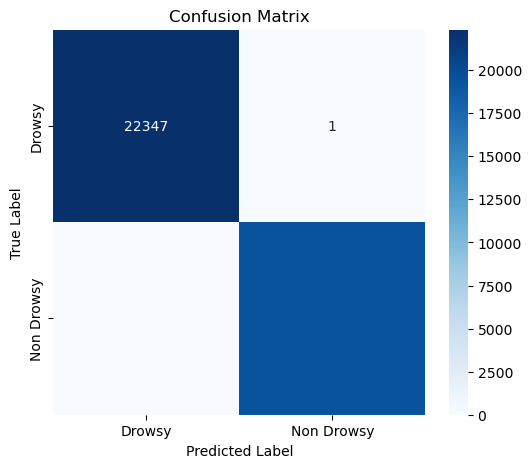

In [8]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Generate classification report
report = classification_report(y_test, y_pred, target_names=categories)
print("📄 Classification Report:\n", report)

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=categories, yticklabels=categories)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()
